# Wadi Ghadir magnetics – cross-section, forward modelling and inversion with pyGIMLi and SimPEG

**Wadi Ghadir, Eastern Desert, Egypt · total-field magnetic anomaly**

**Written by Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook continues the magnetic chain (`notebooks/02_Magnetic_Processing.ipynb`, `wghadir.chains.MagneticChain`).
It starts from the gridded total-field anomaly (TMA = TMI − IGRF-14) and its reduction to the pole and models the
strongest anomaly of the survey, in the south-west:

| Step | Tool | Content |
|---:|---|---|
| 1 | xarray | Load the TMA and RTP grids, choose the modelling window and a cross-section A–B |
| 2 | xarray | TMA, RTP and the readings along the section |
| 3 | **pyGIMLi** | 3-D forward model of a magnetic block (Holstein 2007 kernels) with a least-squares susceptibility |
| 4 | **pyGIMLi** | Depth-weighted smooth 3-D susceptibility inversion of the window, with an L-curve |
| 5 | **SimPEG** | 3-D susceptibility inversion with χ ≥ 0 (integral formulation, Choclo kernels) |
| 6 | | Both models along the section A–B |
| 7 | | Export of profiles, models and figures to `outputs/modelling_magnetic/` |

**Read the results with care.** A magnetic anomaly can be explained by infinitely many susceptibility models, and
magnetic data resolve depth even more poorly than gravity data. All models below assume induced magnetisation along
the IGRF-14 field (I ≈ 36.7°, D ≈ 4.2°); remanence would change them. They show where magnetic material is likely,
not the true shape of geological bodies.

As in the other notebooks, every step has **✏️ PARAMETERS**, **▶ PROCESSING** and **📊 RESULT** cells.

## 0  Set-up

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 82}}
import contextlib
import io
import json
import logging
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy.interpolate import RegularGridInterpolator

REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)            # pyGIMLi and SimPEG progress messages

import discretize
import pygimli as pg
import pyproj
import simpeg
from discretize import TensorMesh
from pygimli.physics.gravimetry import MagneticsModelling, depthWeighting
from simpeg import data, data_misfit, directives, inverse_problem, inversion, maps, optimization, regularization
from simpeg.potential_fields import magnetics

GRID_DIR = os.path.join(REPO, "outputs", "grids")
OUT_DIR = os.path.join(REPO, "outputs", "modelling_magnetic")
os.makedirs(OUT_DIR, exist_ok=True)
UTM = pyproj.Proj("EPSG:32636")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("pyGIMLi", pg.__version__, "| SimPEG", simpeg.__version__, "| discretize", discretize.__version__)

No module named 'pyvista'.
You need to install this optional dependency to properly visualize 3D data.
No module named 'trame'.
You need to install this optional dependency to use interactive 3D visualizations within Jupyter notebooks.
No module named 'pyvista'.
You need to install this optional dependency to properly visualize 3D data.
No module named 'pyvista'.
You need to install this optional dependency to properly visualize 3D data.
pyGIMLi 1.6.1 | SimPEG 0.25.2 | discretize 0.12.0


## 1  Grids, field direction, window and section

The TMA and RTP grids (50 m, UTM 36N) and the inducing field come from the magnetic chain (`outputs/grids/mag_*.nc`,
`outputs/magnetics_summary.json`); run `scripts/run_magnetics.py` first if they are missing. The modelling window is
a square around the strongest anomaly; the 3-D models use the TMA inside it, resampled every `DATA_STEP_M`.
The section A–B runs north–south across the anomaly, the direction in which an inclined field makes it most asymmetric.

In [2]:
# ✏️ PARAMETERS – edit and re-run from here
CENTER_LONLAT = (34.7490, 24.7260)     # centre of the modelling window (lon, lat)
HALF_WINDOW_M = 4000.0                 # half the side of the window
DATA_STEP_M = 250.0                    # data spacing used by the 3-D models
SENSOR_HEIGHT_M = 2.0                  # magnetometer above the ground
A_LONLAT = (34.7490, 24.7000)          # section start (lon, lat)
B_LONLAT = (34.7490, 24.7520)          # section end
SAMPLE_M = 100.0                       # spacing of the section points
REMOVE_PLANE = True                    # remove a planar trend of the window (the anomaly continues beyond it)

In [3]:
# ▶ PROCESSING
tma = xr.open_dataset(os.path.join(GRID_DIR, "mag_tma.nc"))
rtp = xr.open_dataset(os.path.join(GRID_DIR, "mag_rtp.nc"))
TMA, RTP = tma[list(tma.data_vars)[0]], rtp[list(rtp.data_vars)[0]]
summ = json.load(open(os.path.join(REPO, "outputs", "magnetics_summary.json")))
INC, DEC = summ["inc"], summ["dec"]
qc = pd.read_csv(os.path.join(REPO, "outputs", "tables", "30_mag_readings_qc.csv"))
acc = qc[qc["accepted"]]
F_NT = float(acc["igrf_F_nT"].median())
ce, cn = UTM(*CENTER_LONLAT)
nodes_e = np.arange(ce - HALF_WINDOW_M, ce + HALF_WINDOW_M + 1, DATA_STEP_M)
nodes_n = np.arange(cn - HALF_WINDOW_M, cn + HALF_WINDOW_M + 1, DATA_STEP_M)
win = TMA.interp(easting=nodes_e, northing=nodes_n)
E, N = np.meshgrid(nodes_e, nodes_n)
ok = np.isfinite(win.values)
level = float(np.median(win.values[ok]))
d_obs = win.values[ok] - level                                   # the anomaly has no absolute level
xyz = np.column_stack([E[ok] - ce, N[ok] - cn, np.full(ok.sum(), SENSOR_HEIGHT_M)])   # local metres, z up
plane = np.zeros(3)
if REMOVE_PLANE:
    Ap = np.column_stack([np.ones(len(d_obs)), xyz[:, 0] / 1000, xyz[:, 1] / 1000])
    plane = np.linalg.lstsq(Ap, d_obs, rcond=None)[0]
    d_obs = d_obs - Ap @ plane
print(f"field F = {F_NT:.0f} nT, I = {INC:.2f}°, D = {DEC:.2f}°; window {2 * HALF_WINDOW_M / 1000:g} km, "
      f"{ok.sum()} data, {d_obs.min():.0f} … {d_obs.max():.0f} nT after removing the median ({level:.0f} nT)"
      + (f" and a plane ({plane[1]:.0f} nT/km east, {plane[2]:.0f} nT/km north)" if REMOVE_PLANE else ""))

field F = 41971 nT, I = 36.74°, D = 4.22°; window 8 km, 809 data, -506 … 1049 nT after removing the median (-204 nT) and a plane (-10 nT/km east, -68 nT/km north)


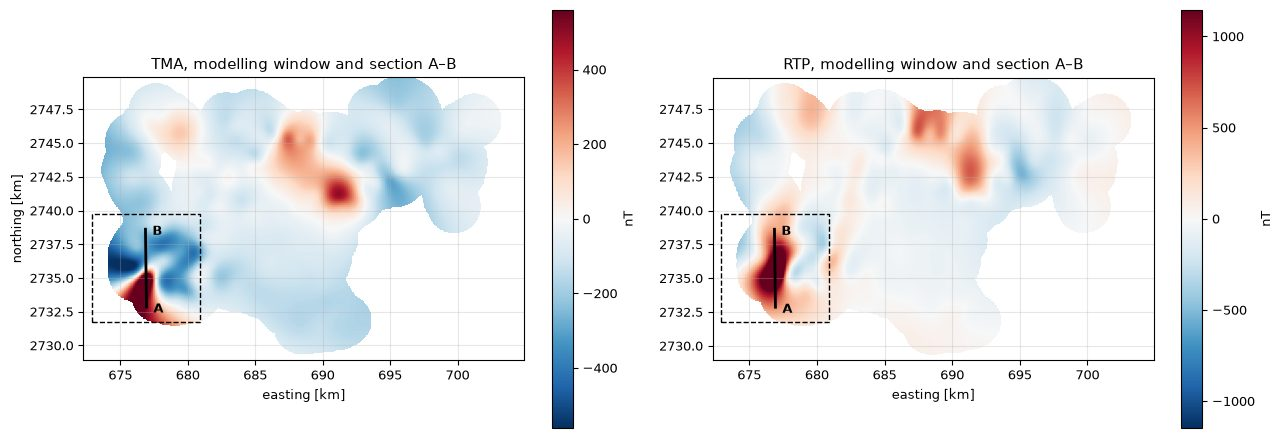

In [4]:
# 📊 RESULT
(ea, na), (eb, nb) = UTM(*A_LONLAT), UTM(*B_LONLAT)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, g, title in ((axes[0], TMA, "TMA"), (axes[1], RTP, "RTP")):
    lim = np.nanpercentile(np.abs(g.values), 99)
    m = ax.pcolormesh(g.easting / 1000, g.northing / 1000, g, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.plot(np.array([-1, 1, 1, -1, -1]) * HALF_WINDOW_M / 1000 + ce / 1000, np.array([-1, -1, 1, 1, -1]) * HALF_WINDOW_M / 1000 + cn / 1000, "k--", lw=1)
    ax.plot([ea / 1000, eb / 1000], [na / 1000, nb / 1000], "k-", lw=2)
    ax.annotate("A", (ea / 1000, na / 1000), fontweight="bold", xytext=(5, -4), textcoords="offset points")
    ax.annotate("B", (eb / 1000, nb / 1000), fontweight="bold", xytext=(5, -4), textcoords="offset points")
    ax.set(aspect="equal", title=f"{title}, modelling window and section A–B", xlabel="easting [km]")
    plt.colorbar(m, ax=ax, label="nT", shrink=0.8)
axes[0].set_ylabel("northing [km]")
plt.tight_layout()

## 2  The anomaly along the section

TMA and RTP are interpolated along A–B; readings within `CORRIDOR_M` of the line are projected onto it. The RTP
puts the high above the source; the TMA shows the high to the south and the low to the north typical of a 37° field.

In [5]:
# ✏️ PARAMETERS – edit and re-run from here
CORRIDOR_M = 300.0

In [6]:
# ▶ PROCESSING
L = np.hypot(eb - ea, nb - na)
dist = np.arange(0.0, L + 1e-6, SAMPLE_M)
pe, pn = ea + dist / L * (eb - ea), na + dist / L * (nb - na)
at = dict(easting=xr.DataArray(pe, dims="p"), northing=xr.DataArray(pn, dims="p"))
sec_tma, sec_rtp = TMA.interp(**at).values, RTP.interp(**at).values
ue, un = (eb - ea) / L, (nb - na) / L
t = (acc["utm_e"] - ea) * ue + (acc["utm_n"] - na) * un
off = -(acc["utm_e"] - ea) * un + (acc["utm_n"] - na) * ue
near = acc[(t >= 0) & (t <= L) & (off.abs() <= CORRIDOR_M)]
t_near = ((near["utm_e"] - ea) * ue + (near["utm_n"] - na) * un).values
print(f"section {L / 1000:.2f} km; {len(near)} readings within ±{CORRIDOR_M:g} m")

section 5.76 km; 563 readings within ±300 m


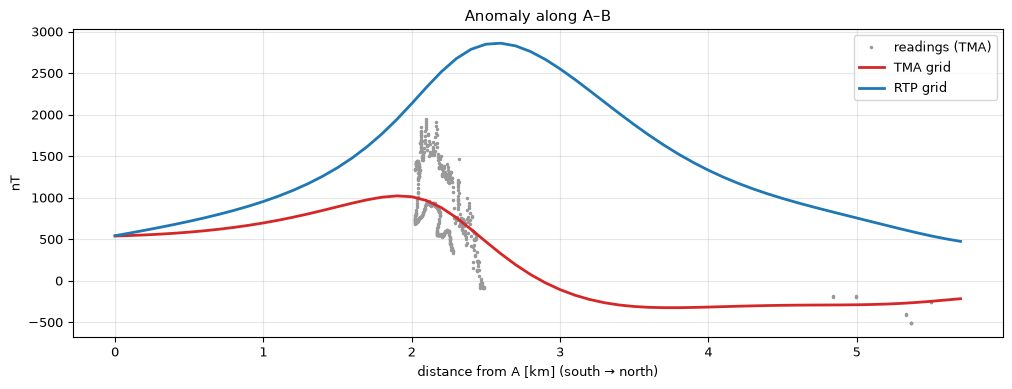

In [7]:
# 📊 RESULT
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_near / 1000, near["tma_nT"], ".", color="0.6", ms=3, label="readings (TMA)")
ax.plot(dist / 1000, sec_tma, "-", color="C3", lw=2, label="TMA grid")
ax.plot(dist / 1000, sec_rtp, "-", color="C0", lw=2, label="RTP grid")
ax.set(xlabel="distance from A [km] (south → north)", ylabel="nT", title="Anomaly along A–B")
ax.legend()
plt.show()

## 3  Forward modelling with pyGIMLi (3-D)

A hypothesis: one magnetic block below the anomaly, magnetised by the present field. Its total-field anomaly is
computed with pyGIMLi's `MagneticsModelling` (Holstein 2007 closed-form kernels for hexahedra) on a 3-D mesh. The
response is linear in the susceptibility, so the best χ of the block follows by least squares. With
`BLOCK_SEARCH = True` the position, size and depth range of the block are also searched over a small grid of
candidates (thousands of blocks, each a sum of kernel columns). The same mesh and kernel are used by the inversion
in step 4. The kernel takes about a minute the first time; pyGIMLi caches it.

In [8]:
# ✏️ PARAMETERS – edit and re-run from here
BLOCK = dict(center_lonlat=(34.7492, 24.7231), size_e_m=1500.0, size_n_m=1500.0, top_m=150.0, bottom_m=1000.0)
BLOCK_SEARCH = True                  # search position, size and depth range around BLOCK
MESH_DX_M = 400.0                    # horizontal cell size of the pyGIMLi mesh
MESH_PAD_M = 1200.0                  # padding beyond the window
MESH_Z_EDGES_M = np.arange(0.0, 3001.0, 250.0)

In [9]:
# ▶ PROCESSING
xe = np.arange(-HALF_WINDOW_M - MESH_PAD_M, HALF_WINDOW_M + MESH_PAD_M + 1, MESH_DX_M)
mesh3 = pg.createGrid(xe, xe, -MESH_Z_EDGES_M[::-1])               # z up: depths are negative
Ir, Dr = np.radians(INC), np.radians(DEC)
igrf_xyz = [F_NT * np.cos(Ir) * np.cos(Dr), F_NT * np.cos(Ir) * np.sin(Dr), F_NT * np.sin(Ir)]   # north, east, down
fop3 = MagneticsModelling(mesh3, xyz, cmp=["TFA"], igrf=igrf_xyz)
tic = time.time()
with contextlib.redirect_stdout(io.StringIO()):                     # silence the kernel progress bar
    fop3.response(pg.Vector(mesh3.cellCount(), 0.0))
cc3 = np.array([[c.center().x(), c.center().y(), -c.center().z()] for c in mesh3.cells()])   # x east, y north, depth
K = np.squeeze(np.asarray(fop3.kernel[:, 0, :]))
K = K if K.shape[0] == len(d_obs) else K.T                         # data × cells: TFA of each cell for χ = 1 SI
dc = d_obs - d_obs.mean()
def block_fit(e0, n0, se, sn, top, bot):
    cells = ((np.abs(cc3[:, 0] - e0) <= se / 2) & (np.abs(cc3[:, 1] - n0) <= sn / 2) & (cc3[:, 2] >= top) & (cc3[:, 2] <= bot))
    if not cells.any():
        return None
    u = K[:, cells].sum(axis=1)
    uc = u - u.mean()
    chi = float(uc @ dc / (uc @ uc))
    return chi, float(np.sqrt(np.mean((chi * uc - dc) ** 2))), cells, u
be, bn = UTM(*BLOCK["center_lonlat"])
best = (BLOCK["size_e_m"], BLOCK["size_n_m"], BLOCK["top_m"], BLOCK["bottom_m"], be - ce, bn - cn)
if BLOCK_SEARCH:
    tried, top_rms = 0, np.inf
    for de in (-800, -400, 0, 400, 800):
        for dn in (-1600, -1200, -800, -400, 0, 400, 800):
            for se in (1000.0, 2000.0, 3000.0):
                for sn in (1000.0, 2000.0, 3000.0):
                    for top in (100.0, 250.0, 500.0):
                        for bot in (750.0, 1500.0, 3000.0):
                            r = block_fit(be - ce + de, bn - cn + dn, se, sn, top, bot)
                            tried += 1
                            if r and 0 < r[0] <= 0.5 and r[1] < top_rms:
                                top_rms, best = r[1], (se, sn, top, bot, be - ce + de, bn - cn + dn)
    print(f"block search: {tried} candidate blocks")
BLOCK.update(size_e_m=best[0], size_n_m=best[1], top_m=best[2], bottom_m=best[3])
be, bn = best[4] + ce, best[5] + cn
BLOCK["center_lonlat"] = tuple(round(float(v), 5) for v in UTM(be, bn, inverse=True))
chi_block, _, inblock, unit = block_fit(be - ce, bn - cn, *best[:4])
d_fwd = chi_block * unit
d_fwd += d_obs.mean() - d_fwd.mean()
print(f"pyGIMLi mesh {mesh3.cellCount()} cells; kernel and search {time.time() - tic:.0f} s; block {BLOCK}; cells {inblock.sum()}; "
      f"least-squares χ = {chi_block:.4f} SI; rms misfit {np.sqrt(np.mean((d_fwd - d_obs) ** 2)):.0f} nT "
      f"(data rms {np.sqrt(np.mean((d_obs - d_obs.mean()) ** 2)):.0f} nT)")

block search: 2835 candidate blocks
pyGIMLi mesh 8112 cells; kernel and search 3 s; block {'center_lonlat': (34.7492, 24.7231), 'size_e_m': 1000.0, 'size_n_m': 3000.0, 'top_m': 500.0, 'bottom_m': 1500.0}; cells 64; least-squares χ = 0.2743 SI; rms misfit 194 nT (data rms 272 nT)


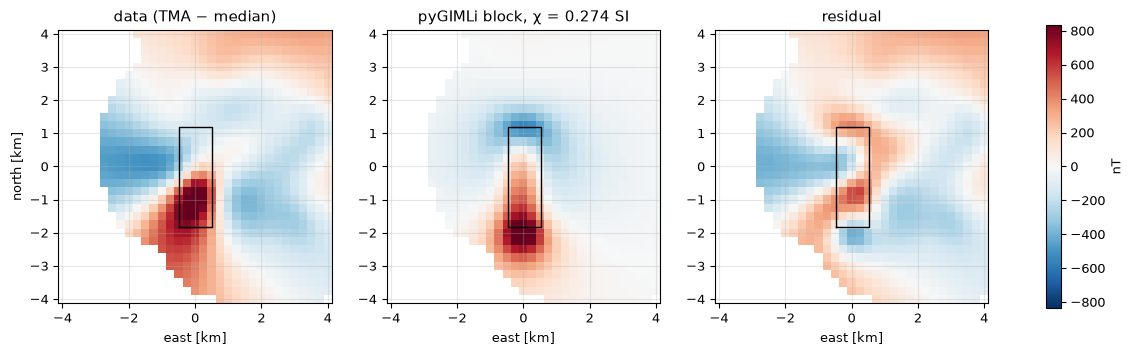

In [10]:
# 📊 RESULT
def to_grid(v):
    g = np.full(ok.shape, np.nan)
    g[ok] = v
    return g

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
lim = np.nanpercentile(np.abs(d_obs), 99)
for ax, v, title in ((axes[0], d_obs, "data (TMA − median)"), (axes[1], d_fwd, f"pyGIMLi block, χ = {chi_block:.3f} SI"), (axes[2], d_obs - d_fwd, "residual")):
    m = ax.pcolormesh((nodes_e - ce) / 1000, (nodes_n - cn) / 1000, to_grid(v), cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.set(aspect="equal", title=title, xlabel="east [km]")
    ax.plot([(be - ce - BLOCK["size_e_m"] / 2) / 1000, (be - ce + BLOCK["size_e_m"] / 2) / 1000, (be - ce + BLOCK["size_e_m"] / 2) / 1000, (be - ce - BLOCK["size_e_m"] / 2) / 1000, (be - ce - BLOCK["size_e_m"] / 2) / 1000],
            [(bn - cn - BLOCK["size_n_m"] / 2) / 1000, (bn - cn - BLOCK["size_n_m"] / 2) / 1000, (bn - cn + BLOCK["size_n_m"] / 2) / 1000, (bn - cn + BLOCK["size_n_m"] / 2) / 1000, (bn - cn - BLOCK["size_n_m"] / 2) / 1000], "k-", lw=1)
axes[0].set_ylabel("north [km]")
plt.colorbar(m, ax=axes, label="nT", shrink=0.8)
plt.show()

## 4  3-D inversion with pyGIMLi

`pygimli.Inversion` finds the smallest susceptibility model on the mesh of step 3 that fits the data to their
error (`cType=0`, linear transforms: χ may become negative here). A Li & Oldenburg depth weighting
(`depthWeighting`, power 1.5 for the 1/r³ decay of magnetic kernels in 3-D) keeps the susceptibility from collecting
at the surface. With `LAMBDA = "auto"` the λ of the L-curve whose χ² is closest to 1 is used. Try `CTYPE = 1`
(smoothest model): with these data it pushes the susceptibility to the bottom of the mesh.

In [11]:
# ✏️ PARAMETERS – edit and re-run from here
LAMBDA = "auto"
ERROR_NT = 15.0
DW_Z0_M, DW_POWER = 200.0, 1.5
LCURVE_LAMBDAS = (1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6)
CTYPE = 0

In [12]:
# ▶ PROCESSING
def invert3d(lam):
    inv = pg.Inversion(fop=fop3, verbose=False)
    inv.setRegularization(cType=CTYPE, trans="lin")
    inv.modelTrans = pg.trans.Trans()
    inv.dataTrans = pg.trans.Trans()
    inv.setConstraintWeights(depthWeighting(mesh3, z0=DW_Z0_M, power=DW_POWER, cell=(CTYPE == 0)))
    with contextlib.redirect_stdout(io.StringIO()):
        m = np.asarray(inv.run(d_obs, absoluteError=ERROR_NT, lam=lam, startModel=0.0, maxIter=10))
    r = np.asarray(inv.response)
    return m, r, float(np.mean(((r - d_obs) / ERROR_NT) ** 2))

tic = time.time()
lcurve = []
for lam in LCURVE_LAMBDAS:
    m, r, chi2 = invert3d(lam)
    lcurve.append(dict(lam=lam, chi2=chi2, rms_nT=np.sqrt(np.mean((r - d_obs) ** 2)), model_rms=np.sqrt(np.mean(m ** 2))))
lcurve = pd.DataFrame(lcurve)
if LAMBDA == "auto":
    LAMBDA = float(lcurve.iloc[(np.log(lcurve["chi2"])).abs().argmin()]["lam"])
chi_pg, d_pg, chi2_pg = invert3d(LAMBDA)
print(f"pyGIMLi: λ = {LAMBDA:g}, χ² = {chi2_pg:.2f}, rms {np.sqrt(np.mean((d_pg - d_obs) ** 2)):.1f} nT, "
      f"χ {chi_pg.min():.4f} … {chi_pg.max():.4f} SI ({time.time() - tic:.0f} s with the L-curve)")
lcurve.round({"chi2": 3, "rms_nT": 1, "model_rms": 5})

pyGIMLi: λ = 100000, χ² = 0.84, rms 13.8 nT, χ -0.0956 … 0.2309 SI (8 s with the L-curve)


,lam,chi2,rms_nT,model_rms
0,1000.0,0.012,1.7,0.01644
1,3000.0,0.039,3.0,0.01853
2,10000.0,0.075,4.1,0.02128
3,30000.0,0.202,6.7,0.02507
4,100000.0,0.842,13.8,0.02913
5,300000.0,3.941,29.8,0.03119
6,1000000.0,19.712,66.6,0.02587


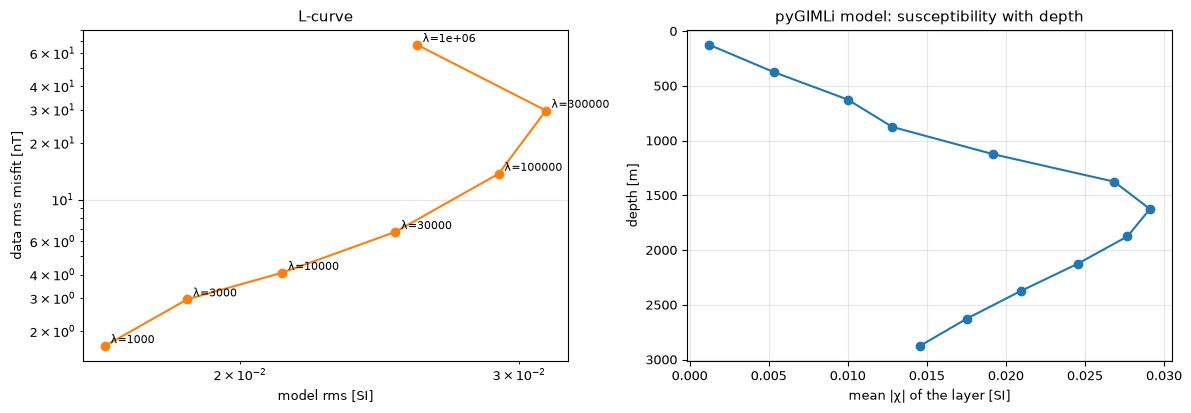

In [13]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].loglog(lcurve["model_rms"], lcurve["rms_nT"], "o-", color="C1")
for r in lcurve.itertuples():
    axes[0].annotate(f"λ={r.lam:g}", (r.model_rms, r.rms_nT), fontsize=8, xytext=(4, 2), textcoords="offset points")
axes[0].set(xlabel="model rms [SI]", ylabel="data rms misfit [nT]", title="L-curve")
nz, ny, nx = len(MESH_Z_EDGES_M) - 1, len(xe) - 1, len(xe) - 1
vol = chi_pg.reshape(nz, ny, nx)[::-1]          # top layer first
depths = (MESH_Z_EDGES_M[:-1] + MESH_Z_EDGES_M[1:]) / 2
axes[1].plot(np.abs(vol).mean(axis=(1, 2)), depths, "o-")
axes[1].invert_yaxis()
axes[1].set(xlabel="mean |χ| of the layer [SI]", ylabel="depth [m]", title="pyGIMLi model: susceptibility with depth")
plt.tight_layout()

## 5  3-D inversion with SimPEG

SimPEG inverts the same data on a finer tensor mesh with the integral formulation and Choclo kernels. Settings:

* **Model:** susceptibility in SI, bounded to `BOUNDS` (χ ≥ 0 by default).
* **Regularisation:** smallness plus smoothness (`WeightedLeastSquares`) with sensitivity weighting.
* **Optimisation:** projected Gauss–Newton (respects the bounds), β cooling until χ² = number of data.

In [14]:
# ✏️ PARAMETERS – edit and re-run from here
CORE_DX_M, CORE_DZ_M = 200.0, 100.0
N_LAYERS = 30
BOUNDS = (0.0, 1.0)                    # SI
ERROR_NT_3D = 15.0

In [15]:
# ▶ PROCESSING
nc = int(round(2 * HALF_WINDOW_M / CORE_DX_M))
hx = [(CORE_DX_M, 5, -1.3), (CORE_DX_M, nc), (CORE_DX_M, 5, 1.3)]
hz = [(CORE_DZ_M, 4, -1.3), (CORE_DZ_M, N_LAYERS)]
mesh_sp = TensorMesh([hx, hx, hz], origin="CCN")
rx = magnetics.receivers.Point(xyz, components="tmi")
src = magnetics.sources.UniformBackgroundField(receiver_list=[rx], amplitude=F_NT, inclination=INC, declination=DEC)
survey = magnetics.survey.Survey(src)
sim = magnetics.simulation.Simulation3DIntegral(survey=survey, mesh=mesh_sp, chiMap=maps.IdentityMap(nP=mesh_sp.n_cells),
                                                engine="choclo", store_sensitivities="ram")
dmis = data_misfit.L2DataMisfit(data=data.Data(survey, dobs=d_obs, standard_deviation=np.full(len(d_obs), ERROR_NT_3D)), simulation=sim)
reg = regularization.WeightedLeastSquares(mesh_sp)
opt = optimization.ProjectedGNCG(maxIter=15, lower=BOUNDS[0], upper=BOUNDS[1], maxIterLS=20, cg_maxiter=30, cg_rtol=1e-3)
dirs = [directives.UpdateSensitivityWeights(every_iteration=False), directives.BetaEstimate_ByEig(beta0_ratio=10),
        directives.BetaSchedule(coolingFactor=5, coolingRate=1), directives.UpdatePreconditioner(), directives.TargetMisfit(chifact=1)]
tic = time.time()
with contextlib.redirect_stdout(io.StringIO()):
    chi_sp = inversion.BaseInversion(inverse_problem.BaseInvProblem(dmis, reg, opt), directiveList=dirs).run(np.full(mesh_sp.n_cells, 1e-4))
d_sp = sim.dpred(chi_sp)
sp_seconds = time.time() - tic
print(f"SimPEG: {len(d_obs)} data, {mesh_sp.n_cells} cells {mesh_sp.shape_cells}, {sp_seconds:.0f} s; "
      f"rms misfit {np.sqrt(np.mean((d_sp - d_obs) ** 2)):.1f} nT; χ {chi_sp.min():.4f} … {chi_sp.max():.4f} SI")

SimPEG: 809 data, 85000 cells (50, 50, 34), 10 s; rms misfit 13.2 nT; χ 0.0000 … 0.2305 SI


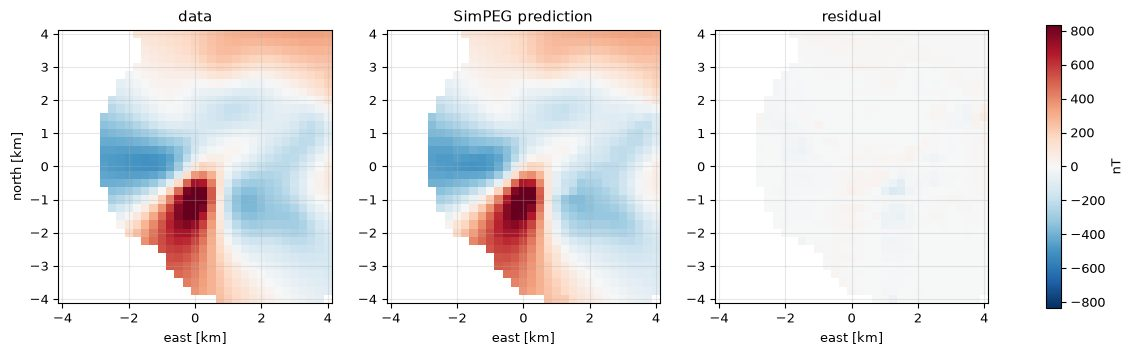

In [16]:
# 📊 RESULT
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, v, title in ((axes[0], d_obs, "data"), (axes[1], d_sp, "SimPEG prediction"), (axes[2], d_obs - d_sp, "residual")):
    m = ax.pcolormesh((nodes_e - ce) / 1000, (nodes_n - cn) / 1000, to_grid(v), cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.set(aspect="equal", title=title, xlabel="east [km]")
axes[0].set_ylabel("north [km]")
plt.colorbar(m, ax=axes, label="nT", shrink=0.8)
plt.show()

## 6  The models along the section A–B

Both 3-D models are cut along A–B; the data and the responses are interpolated along the same line. pyGIMLi (smooth,
χ may be negative) and SimPEG (bounded, χ ≥ 0) put magnetic material below the RTP high; how deep it reaches is
poorly constrained by the data.

In [17]:
# ▶ PROCESSING
sx, sy = pe - ce, pn - cn
def along(v):                                    # a data-point field along the section
    g = xr.DataArray(to_grid(v), coords={"northing": nodes_n, "easting": nodes_e}, dims=("northing", "easting"))
    return g.interp(**at).values
p_obs, p_pg, p_sp, p_fwd = along(d_obs), along(d_pg), along(d_sp), along(d_fwd)
zc = np.arange(25.0, 2500.0, 50.0)
XX, ZZ = np.meshgrid(dist, zc)
xc3, yc3 = (xe[:-1] + xe[1:]) / 2, (xe[:-1] + xe[1:]) / 2
interp_pg = RegularGridInterpolator((depths, yc3, xc3), vol, bounds_error=False, fill_value=np.nan)
sec_pg = interp_pg(np.column_stack([np.clip(ZZ.ravel(), depths[0], depths[-1]), np.interp(XX.ravel(), dist, sy), np.interp(XX.ravel(), dist, sx)])).reshape(XX.shape)
cx, cy, cz = mesh_sp.cell_centers_x, mesh_sp.cell_centers_y, mesh_sp.cell_centers_z
vol_sp = chi_sp.reshape(mesh_sp.shape_cells, order="F")
interp_sp = RegularGridInterpolator((cx, cy, cz), vol_sp, bounds_error=False, fill_value=np.nan)
sec_sp = interp_sp(np.column_stack([np.interp(XX.ravel(), dist, sx), np.interp(XX.ravel(), dist, sy), np.clip(-ZZ.ravel(), cz[0], cz[-1])])).reshape(XX.shape)
print(f"section: pyGIMLi χ {np.nanmin(sec_pg):.4f} … {np.nanmax(sec_pg):.4f}, SimPEG χ {np.nanmin(sec_sp):.4f} … {np.nanmax(sec_sp):.4f} SI")

section: pyGIMLi χ -0.0155 … 0.2264, SimPEG χ 0.0000 … 0.2249 SI


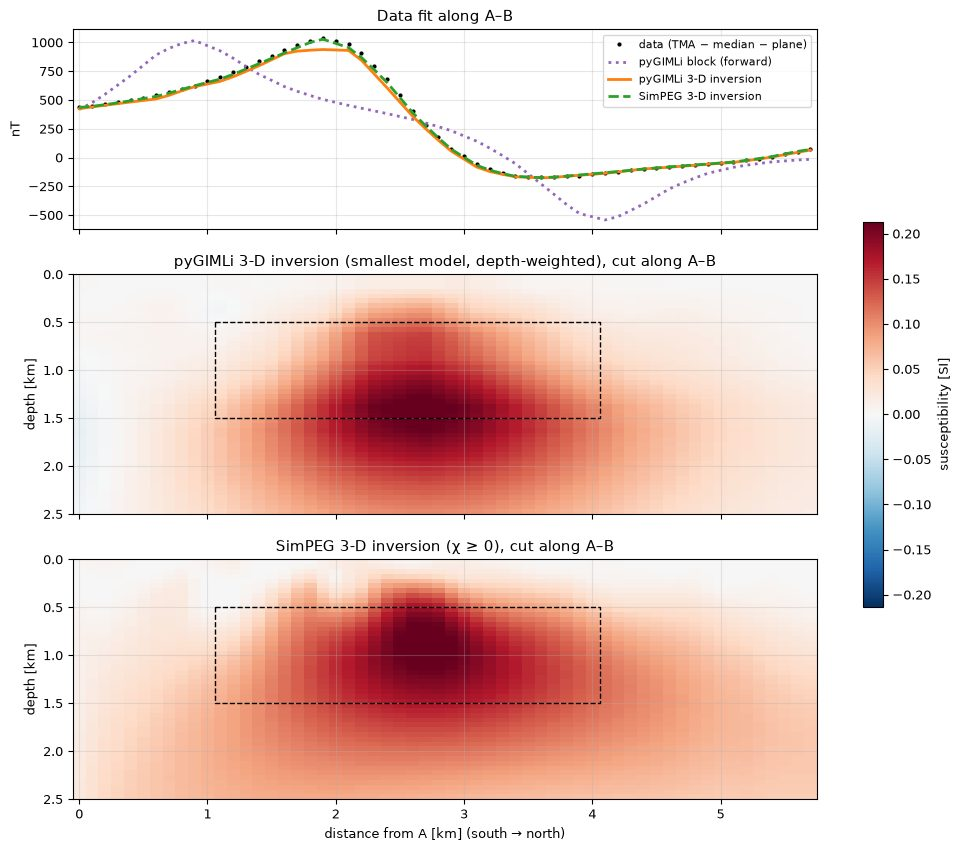

In [18]:
# 📊 RESULT
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1.2, 1.2]})
axes[0].plot(dist / 1000, p_obs, "k.", ms=4, label="data (TMA − median − plane)" if REMOVE_PLANE else "data (TMA − median)")
axes[0].plot(dist / 1000, p_fwd, ":", color="C4", lw=2, label="pyGIMLi block (forward)")
axes[0].plot(dist / 1000, p_pg, "-", color="C1", lw=2, label="pyGIMLi 3-D inversion")
axes[0].plot(dist / 1000, p_sp, "--", color="C2", lw=2, label="SimPEG 3-D inversion")
axes[0].set(ylabel="nT", title="Data fit along A–B")
axes[0].legend(fontsize=8)
vmax = np.nanpercentile(np.abs(np.concatenate([sec_pg.ravel(), sec_sp.ravel()])), 99)
pc = axes[1].pcolormesh(dist / 1000, zc / 1000, sec_pg, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto")
axes[1].set(ylim=(2.5, 0), ylabel="depth [km]", title="pyGIMLi 3-D inversion (smallest model, depth-weighted), cut along A–B")
axes[2].pcolormesh(dist / 1000, zc / 1000, sec_sp, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto")
axes[2].set(ylim=(2.5, 0), xlabel="distance from A [km] (south → north)", ylabel="depth [km]", title="SimPEG 3-D inversion (χ ≥ 0), cut along A–B")
bt = ((be - ea) * ue + (bn - na) * un) / 1000
for ax in axes[1:]:
    ax.plot([bt - BLOCK["size_n_m"] / 2000, bt + BLOCK["size_n_m"] / 2000, bt + BLOCK["size_n_m"] / 2000, bt - BLOCK["size_n_m"] / 2000, bt - BLOCK["size_n_m"] / 2000],
            [BLOCK["top_m"] / 1000, BLOCK["top_m"] / 1000, BLOCK["bottom_m"] / 1000, BLOCK["bottom_m"] / 1000, BLOCK["top_m"] / 1000], "k--", lw=1)
fig.colorbar(pc, ax=axes, label="susceptibility [SI]", shrink=0.5)
fig.savefig(os.path.join(OUT_DIR, "section_models.png"), dpi=200, bbox_inches="tight")

## 7  Export

Writes `section_profile.csv` (points, data and the three responses), both section models as CSV (distance, depth,
susceptibility), the SimPEG 3-D model with its mesh and `summary.json`, all to `outputs/modelling_magnetic/`.

In [19]:
# ▶ PROCESSING
lon_p, lat_p = UTM(pe, pn, inverse=True)
prof = pd.DataFrame({"distance_m": dist, "lon": lon_p, "lat": lat_p, "tma_grid_nT": sec_tma, "rtp_grid_nT": sec_rtp,
                     "data_nT": p_obs, "pygimli_block_nT": p_fwd, "pygimli_inversion_nT": p_pg, "simpeg_inversion_nT": p_sp})
with open(os.path.join(OUT_DIR, "section_profile.csv"), "w") as fh:
    fh.write("# Wadi Ghadir magnetic section A-B, written by Mohamed Sobh, LIAG. data = TMA - median (and plane) of the window.\n")
    prof.to_csv(fh, index=False, float_format="%.4f")
for name, sec in (("pygimli", sec_pg), ("simpeg", sec_sp)):
    pd.DataFrame({"distance_m": XX.ravel(), "depth_m": ZZ.ravel(), "chi_SI": sec.ravel()}).dropna().to_csv(
        os.path.join(OUT_DIR, f"{name}_section_model.csv"), index=False, float_format="%.6f")
np.savez_compressed(os.path.join(OUT_DIR, "simpeg_3d_model.npz"), chi_SI=chi_sp, hx=mesh_sp.h[0], hy=mesh_sp.h[1], hz=mesh_sp.h[2],
                    origin=mesh_sp.origin, center_utm=[ce, cn], data_xyz=xyz, data_nT=d_obs, predicted_nT=d_sp)
summary = {"written_by": "Mohamed Sobh, LIAG", "field": {"F_nT": F_NT, "inc": INC, "dec": DEC}, "level_removed_nT": level,
           "A_lonlat": A_LONLAT, "B_lonlat": B_LONLAT, "length_m": float(L), "spacing_m": SAMPLE_M,
           "window": {"center_lonlat": CENTER_LONLAT, "half_m": HALF_WINDOW_M, "data": int(len(d_obs)), "step_m": DATA_STEP_M},
           "plane_removed": [float(v) for v in plane], "block": dict(BLOCK, chi_SI=chi_block, rms_nT=float(np.sqrt(np.mean((d_fwd - d_obs) ** 2)))),
           "pygimli": {"lambda": float(LAMBDA), "chi2": chi2_pg, "rms_nT": float(np.sqrt(np.mean((d_pg - d_obs) ** 2))),
                       "cells": mesh3.cellCount(), "depth_weighting": {"z0_m": DW_Z0_M, "power": DW_POWER}},
           "simpeg": {"cells": int(mesh_sp.n_cells), "seconds": round(sp_seconds, 1), "bounds_SI": list(BOUNDS),
                      "rms_nT": float(np.sqrt(np.mean((d_sp - d_obs) ** 2)))}}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=1)
sorted(os.listdir(OUT_DIR))

['pygimli_section_model.csv',
 'section_models.png',
 'section_profile.csv',
 'simpeg_3d_model.npz',
 'simpeg_section_model.csv',
 'summary.json']

---
### References

* Rücker, C., Günther, T. & Wagner, F. M. (2017). pyGIMLi: An open-source library for modelling and inversion in geophysics. *Computers & Geosciences* 109.
* Holstein, H. (2007). Gravimagnetic anomaly formulas for polyhedra of spatially linear media. *Geophysics* 67.
* Cockett, R. et al. (2015). SimPEG: An open source framework for simulation and gradient based parameter estimation in geophysical applications. *Computers & Geosciences* 85.
* Li, Y. & Oldenburg, D. W. (1996). 3-D inversion of magnetic data. *Geophysics* 61.
* Alken, P. et al. (2021). International Geomagnetic Reference Field: the thirteenth generation. *Earth, Planets and Space* 73 (IGRF-14 coefficients: IAGA 2024).

*Written by Mohamed Sobh, LIAG.*